# PathSnap — Decision Tree training (VS Code / local laptop)

This notebook builds a **candidate-road classifier** from the PathSnap training trips, then trains and evaluates a scikit-learn Decision Tree.

**Important:** GPS observations and `.route` entries are not row-aligned. The notebook first aligns GPS observations to the ordered reference route using a monotonic, distance-based sequence alignment. It reports alignment/candidate coverage so poor matches are visible rather than hidden.

- Uses only `train/` trips for fitting and trip-grouped validation.
- Does not read `student_test/` or evaluator test data.
- Scikit-learn DecisionTreeClassifier runs on CPU (GPU runtime does not accelerate it).
- Treat the resulting metrics as development metrics; inspect route overlays and alignment quality before relying on them.

## 1. Install dependencies

Run this cell once in the VS Code notebook kernel. If VS Code asks you to select a kernel, choose the Python environment where these packages are installed.

In [1]:
%pip install -q numpy pandas scipy scikit-learn matplotlib joblib pyproj folium

Note: you may need to restart the kernel to use updated packages.


## 2. Locate the repository / dataset

Option A: clone the hackathon repository into the current notebook folder.  
Option B: set `DATA_ROOT` to the extracted folder containing `train/` and `student_test/`.

If you already have the repository cloned, this cell reuses it.

In [2]:
from pathlib import Path
import subprocess, os, sys

CANDIDATE_ROOTS = [
    Path.cwd() / "machine-learning-hackathon" / "data" / "Student folder",
    Path.cwd() / "data" / "Student folder",
    Path.cwd() / "Student folder",
]

DATA_ROOT = next((p for p in CANDIDATE_ROOTS if (p / "train").is_dir()), None)

if DATA_ROOT is None:
    repo_dir = Path.cwd() / "machine-learning-hackathon"
    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/gitsumchips/machine-learning-hackathon.git",
             str(repo_dir)],
            check=True
        )
    DATA_ROOT = repo_dir / "data" / "Student folder"

if not (DATA_ROOT / "train").is_dir():
    raise FileNotFoundError(
        f"Could not find train/ under {DATA_ROOT}. "
        "Extract the supplied Student folder ZIP, then set DATA_ROOT manually."
    )

print("Using dataset:", DATA_ROOT.resolve())
print("Training trip folders:", len([p for p in (DATA_ROOT / "train").iterdir() if p.is_dir()]))

Using dataset: C:\Users\shiva\Downloads\machine-learning-hackathon\data\Student folder
Training trip folders: 80


## 3. Configuration and data readers

Each `.track` has longitude, latitude, timestamp. `.nodes` has longitude/latitude; node IDs are row positions. `.arcs` has from/to node IDs; arc IDs are row positions. `.route` is an ordered sequence of arc IDs.

In [3]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from pyproj import Transformer
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, log_loss
)
from sklearn.utils.class_weight import compute_sample_weight
from joblib import dump
import matplotlib.pyplot as plt
import time, json, warnings

RANDOM_STATE = 42
K_ROUTE_ALIGNMENT = 25       # nearest route-arc midpoints considered per GPS fix
K_ROAD_CANDIDATES = 30       # nearest road-arc midpoints considered per GPS fix
MAX_CANDIDATE_DISTANCE_M = 120.0
MIN_ALIGNMENT_COVERAGE = 0.70
FEATURE_COLUMNS = [
    "distance_to_arc_m", "heading_difference_deg",
    "heading_cosine", "gps_step_distance_m", "gps_speed_mps",
    "arc_length_m", "arc_bearing_sin", "arc_bearing_cos",
    "from_out_degree", "to_in_degree",
    "midpoint_distance_m", "gps_delta_time_s"
]

def read_ws(path, names, dtype=float):
    df = pd.read_csv(path, sep=r"\s+", engine="python", header=None, names=names, dtype=dtype)
    if df.shape[1] != len(names):
        raise ValueError(f"{path}: expected {len(names)} columns, got {df.shape[1]}")
    return df

def haversine_m(lon1, lat1, lon2, lat2):
    R = 6371008.8
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2-lon1, lat2-lat1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def bearing_deg(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    y = np.sin(lon2-lon1)*np.cos(lat2)
    x = np.cos(lat1)*np.sin(lat2)-np.sin(lat1)*np.cos(lat2)*np.cos(lon2-lon1)
    return (np.degrees(np.arctan2(y, x)) + 360) % 360

def point_segment_distance_xy(px, py, ax, ay, bx, by):
    vx, vy = bx-ax, by-ay
    denom = vx*vx + vy*vy
    t = np.divide((px-ax)*vx + (py-ay)*vy, denom,
                  out=np.zeros_like(np.asarray(px, dtype=float)), where=denom > 0)
    t = np.clip(t, 0.0, 1.0)
    qx, qy = ax+t*vx, ay+t*vy
    return np.hypot(px-qx, py-qy)

## 4. Build per-trip features and labels

For each trip:

1. Convert coordinates to a local metric projection (UTM zone inferred from the trip centre).
2. Construct directed road segments from `.nodes` and `.arcs`.
3. Align each GPS observation to an ordered route position using monotonic dynamic programming over nearby route arcs.
4. Generate nearby road candidates and label a candidate positive only when its `arc_id` equals the aligned reference arc for that observation.

The route alignment is an approximation, not a supplied GPS-to-route mapping. The notebook records distance and coverage diagnostics. Review them before trusting the model.

In [4]:
def local_transformers(lon, lat):
    zone = int(np.floor((float(np.nanmedian(lon)) + 180) / 6) + 1)
    epsg = (32600 if float(np.nanmedian(lat)) >= 0 else 32700) + zone
    fwd = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
    return fwd

def align_track_to_route(track_xy, route_arc_ids, arc_mid_xy, arc_a_xy, arc_b_xy):
    # Candidate route positions per GPS point, based on nearest route arc midpoints.
    n, m = len(track_xy), len(route_arc_ids)
    if n == 0 or m == 0:
        return np.array([], dtype=int), np.array([], dtype=float)
    route_mid = arc_mid_xy[route_arc_ids]
    tree = cKDTree(route_mid)
    k = min(K_ROUTE_ALIGNMENT, m)
    d_mid, pos = tree.query(track_xy, k=k)
    if k == 1:
        d_mid, pos = d_mid[:, None], pos[:, None]
    # Unique sorted route positions, with point-to-segment emission distances.
    candidates, emissions = [], []
    for i, (x, y) in enumerate(track_xy):
        p = np.unique(np.asarray(pos[i], dtype=int))
        p.sort()
        aids = route_arc_ids[p]
        dist = point_segment_distance_xy(
            np.full(len(p), x), np.full(len(p), y),
            arc_a_xy[aids, 0], arc_a_xy[aids, 1],
            arc_b_xy[aids, 0], arc_b_xy[aids, 1]
        )
        candidates.append(p)
        emissions.append(dist)
    # Dynamic programming: route position may stay or move forward, never backward.
    costs, back = [], []
    costs.append(emissions[0].astype(float))
    back.append(np.full(len(candidates[0]), -1, dtype=int))
    for i in range(1, n):
        prev_pos, curr_pos = candidates[i-1], candidates[i]
        prev_cost = costs[-1]
        cur_cost = np.full(len(curr_pos), np.inf)
        cur_back = np.full(len(curr_pos), -1, dtype=int)
        # Prefix minimum over prior route positions gives best monotonic predecessor.
        order = np.argsort(prev_pos)
        pp, pc = prev_pos[order], prev_cost[order]
        prefix_cost = np.minimum.accumulate(pc)
        prefix_argmin = np.zeros(len(pc), dtype=int)
        best = 0
        for q in range(len(pc)):
            if pc[q] < pc[best]:
                best = q
            prefix_argmin[q] = best
        for j, rp in enumerate(curr_pos):
            valid = np.where(pp <= rp)[0]
            if len(valid):
                q = valid[-1]
                cur_cost[j] = emissions[i][j] + prefix_cost[q]
                cur_back[j] = order[prefix_argmin[q]]
        # If no monotonic transition exists (rare due to candidate truncation), restart softly.
        if not np.isfinite(cur_cost).any():
            cur_cost = emissions[i].astype(float) + np.nanmin(prev_cost)
            cur_back[:] = int(np.nanargmin(prev_cost))
        costs.append(cur_cost)
        back.append(cur_back)
    idx = int(np.nanargmin(costs[-1]))
    chosen_pos = np.zeros(n, dtype=int)
    chosen_dist = np.zeros(n, dtype=float)
    for i in range(n-1, -1, -1):
        chosen_pos[i] = candidates[i][idx]
        chosen_dist[i] = emissions[i][idx]
        if i:
            idx = int(back[i][idx])
            if idx < 0:
                idx = 0
    return chosen_pos, chosen_dist

def build_trip_table(trip_dir):
    trip_id = trip_dir.name
    track = read_ws(trip_dir / f"{trip_id}.track",
                    ["longitude", "latitude", "timestamp_s"], float)
    nodes = read_ws(trip_dir / f"{trip_id}.nodes",
                    ["longitude", "latitude"], float)
    arcs = read_ws(trip_dir / f"{trip_id}.arcs",
                   ["from_node_id", "to_node_id"], np.int64)
    route = read_ws(trip_dir / f"{trip_id}.route", ["arc_id"], np.int64)["arc_id"].to_numpy()

    # Clean invalid track rows; preserve chronological order.
    track = track.replace([np.inf, -np.inf], np.nan).dropna().copy()
    track = track[
        track.longitude.between(-180, 180) & track.latitude.between(-90, 90)
    ].sort_values("timestamp_s", kind="stable").drop_duplicates("timestamp_s").reset_index(drop=True)
    if len(track) < 2 or len(route) == 0:
        raise ValueError(f"{trip_id}: insufficient GPS observations or route labels")
    if route.min() < 0 or route.max() >= len(arcs):
        raise ValueError(f"{trip_id}: route contains invalid arc ID")
    endpoints = arcs[["from_node_id", "to_node_id"]].to_numpy(dtype=int)
    if endpoints.min() < 0 or endpoints.max() >= len(nodes):
        raise ValueError(f"{trip_id}: invalid node reference in arcs")

    transformer = local_transformers(track.longitude, track.latitude)
    tx, ty = transformer.transform(track.longitude.to_numpy(), track.latitude.to_numpy())
    track_xy = np.column_stack([tx, ty])
    nx, ny = transformer.transform(nodes.longitude.to_numpy(), nodes.latitude.to_numpy())
    node_xy = np.column_stack([nx, ny])
    a_ids, b_ids = endpoints.T
    arc_a, arc_b = node_xy[a_ids], node_xy[b_ids]
    arc_mid = (arc_a + arc_b) / 2
    arc_len = np.linalg.norm(arc_b-arc_a, axis=1)
    arc_bearing = bearing_deg(nodes.longitude.to_numpy()[a_ids], nodes.latitude.to_numpy()[a_ids],
                              nodes.longitude.to_numpy()[b_ids], nodes.latitude.to_numpy()[b_ids])
    outdeg = np.bincount(a_ids, minlength=len(nodes))
    indeg = np.bincount(b_ids, minlength=len(nodes))

    matched_route_pos, align_dist = align_track_to_route(
        track_xy, route, arc_mid, arc_a, arc_b
    )
    reference_arc = route[matched_route_pos]

    # GPS motion features.
    dt = np.r_[0.0, np.diff(track.timestamp_s.to_numpy())]
    step = np.r_[0.0, np.linalg.norm(np.diff(track_xy, axis=0), axis=1)]
    gps_bearing = np.r_[0.0, bearing_deg(
        track.longitude.to_numpy()[:-1], track.latitude.to_numpy()[:-1],
        track.longitude.to_numpy()[1:], track.latitude.to_numpy()[1:]
    )]
    gps_speed = np.divide(step, dt, out=np.zeros_like(step), where=dt > 0)

    # Query nearest arc midpoints, then calculate exact point-to-segment distances.
    road_tree = cKDTree(arc_mid)
    k = min(K_ROAD_CANDIDATES, len(arcs))
    _, nearest = road_tree.query(track_xy, k=k)
    if k == 1:
        nearest = nearest[:, None]

    rows = []
    n_obs_with_positive = 0
    for i, cand in enumerate(nearest):
        cand = np.unique(np.asarray(cand, dtype=int))
        x, y = track_xy[i]
        dseg = point_segment_distance_xy(
            np.full(len(cand), x), np.full(len(cand), y),
            arc_a[cand, 0], arc_a[cand, 1], arc_b[cand, 0], arc_b[cand, 1]
        )
        dmid = np.linalg.norm(arc_mid[cand] - track_xy[i], axis=1)
        angle = np.abs((arc_bearing[cand] - gps_bearing[i] + 180) % 360 - 180)
        labels = (cand == reference_arc[i]).astype(np.int8)
        if labels.sum() > 0:
            n_obs_with_positive += 1
        for j, aid in enumerate(cand):
            rows.append({
                "trip_id": trip_id,
                "observation_id": i,
                "arc_id": int(aid),
                "is_match": int(labels[j]),
                "distance_to_arc_m": float(dseg[j]),
                "heading_difference_deg": float(angle[j]),
                "heading_cosine": float(np.cos(np.radians(angle[j]))),
                "gps_step_distance_m": float(step[i]),
                "gps_speed_mps": float(gps_speed[i]),
                "arc_length_m": float(arc_len[aid]),
                "arc_bearing_sin": float(np.sin(np.radians(arc_bearing[aid]))),
                "arc_bearing_cos": float(np.cos(np.radians(arc_bearing[aid]))),
                "from_out_degree": int(outdeg[a_ids[aid]]),
                "to_in_degree": int(indeg[b_ids[aid]]),
                "midpoint_distance_m": float(dmid[j]),
                "gps_delta_time_s": float(dt[i]),
            })
    table = pd.DataFrame(rows)
    coverage = n_obs_with_positive / len(track)
    diagnostics = {
        "trip_id": trip_id, "gps_observations": len(track),
        "route_arcs": len(route), "candidate_rows": len(table),
        "alignment_median_distance_m": float(np.median(align_dist)),
        "alignment_p90_distance_m": float(np.percentile(align_dist, 90)),
        "candidate_positive_coverage": float(coverage),
        "candidate_miss_rate": float(1-coverage),
    }
    return table, diagnostics

## 5. Build the training candidate table

This can take time because each trip may contain a large road graph. Start with all training trips for the actual experiment. For a quick smoke test, set `MAX_TRIPS = 2`, verify outputs, then set it back to `None`.

In [5]:
train_dirs = sorted(p for p in (DATA_ROOT / "train").iterdir() if p.is_dir())
MAX_TRIPS = None  # set to 2 for a quick smoke test
if MAX_TRIPS is not None:
    train_dirs = train_dirs[:MAX_TRIPS]

tables, diagnostics = [], []
for idx, trip_dir in enumerate(train_dirs, 1):
    print(f"[{idx}/{len(train_dirs)}] {trip_dir.name}")
    trip_table, diag = build_trip_table(trip_dir)
    tables.append(trip_table)
    diagnostics.append(diag)

candidate_df = pd.concat(tables, ignore_index=True)
diagnostics_df = pd.DataFrame(diagnostics)
display(diagnostics_df)
print("Candidate table shape:", candidate_df.shape)
print("Positive class fraction:", candidate_df.is_match.mean())

[1/80] 00000001
[2/80] 00000002
[3/80] 00000003
[4/80] 00000004
[5/80] 00000005
[6/80] 00000006
[7/80] 00000008
[8/80] 00000010
[9/80] 00000011
[10/80] 00000012
[11/80] 00000013
[12/80] 00000014
[13/80] 00000016
[14/80] 00000018
[15/80] 00000019
[16/80] 00000020
[17/80] 00000021
[18/80] 00000022
[19/80] 00000024
[20/80] 00000025
[21/80] 00000026
[22/80] 00000027
[23/80] 00000028
[24/80] 00000029
[25/80] 00000031
[26/80] 00000032
[27/80] 00000033
[28/80] 00000034
[29/80] 00000035
[30/80] 00000036
[31/80] 00000037
[32/80] 00000038
[33/80] 00000039
[34/80] 00000041
[35/80] 00000042
[36/80] 00000043
[37/80] 00000044
[38/80] 00000045
[39/80] 00000046
[40/80] 00000047
[41/80] 00000048
[42/80] 00000050
[43/80] 00000051
[44/80] 00000053
[45/80] 00000054
[46/80] 00000055
[47/80] 00000057
[48/80] 00000058
[49/80] 00000060
[50/80] 00000061
[51/80] 00000062
[52/80] 00000063
[53/80] 00000064
[54/80] 00000066
[55/80] 00000068
[56/80] 00000069
[57/80] 00000070
[58/80] 00000071
[59/80] 00000072
[60/80

,trip_id,gps_observations,route_arcs,candidate_rows,alignment_median_distance_m,alignment_p90_distance_m,candidate_positive_coverage,candidate_miss_rate
0,00000001,1315,525,39450,4.297891,10.253191,0.892776,0.107224
1,00000002,7243,262,217290,5.774628,97.787820,0.920337,0.079663
2,00000003,821,79,24630,4.457845,11.823338,0.867235,0.132765
3,00000004,1064,320,31920,8.519107,25.801672,0.989662,0.010338
4,00000005,1045,105,31350,4.529081,11.015683,0.989474,0.010526
...,...,...,...,...,...,...,...,...
75,00000095,1551,306,46530,3.981820,10.380729,0.996132,0.003868
76,00000096,3271,456,98130,4.457433,12.321443,0.961785,0.038215
77,00000097,1740,444,52200,3.637185,9.089117,0.975862,0.024138
78,00000098,5584,1003,167520,5.147224,12.772510,0.991762,0.008238


Candidate table shape: (6252510, 16)
Positive class fraction: 0.03151310433729814


## 6. Inspect label alignment and candidate coverage

Do not proceed blindly if alignment distances are very large or candidate miss rate is high. A low candidate miss rate means the reference arc was included among the generated candidates for most observations; it does not prove the route alignment is correct.

In [6]:
display(diagnostics_df.describe(include="all"))
print("Trips with alignment median > 50m:",
      int((diagnostics_df.alignment_median_distance_m > 50).sum()))
print("Overall candidate miss rate:",
      1 - candidate_df.groupby(["trip_id", "observation_id"]).is_match.max().mean())

,trip_id,gps_observations,route_arcs,candidate_rows,alignment_median_distance_m,alignment_p90_distance_m,candidate_positive_coverage,candidate_miss_rate
count,80,80.000000,80.000000,80.000000,80.000000,80.000000,80.000000,80.000000
unique,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,00000001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2605.212500,391.700000,78156.375000,8.162154,18.163876,0.965424,0.034576
std,NaN,3312.345399,361.165497,99370.361973,19.919155,26.752318,0.067138,0.067138
min,NaN,361.000000,59.000000,10830.000000,3.448296,8.695960,0.472621,0.000000
25%,NaN,945.750000,168.250000,28372.500000,4.292367,10.716290,0.961183,0.002314
50%,NaN,1529.000000,280.000000,45870.000000,4.636443,11.834858,0.983568,0.016432
75%,NaN,2792.750000,480.500000,83782.500000,5.553856,14.675333,0.997686,0.038817


Trips with alignment median > 50m: 2
Overall candidate miss rate: 0.054606869881055786


## 7. Train / validation split by trip

All candidate rows from one trip stay in the same partition. This avoids putting near-duplicate observations from the same trip in both training and validation.

In [7]:
X_raw = candidate_df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
y = candidate_df["is_match"].astype(int)
groups = candidate_df["trip_id"].astype(str)

if y.nunique() != 2:
    raise ValueError("Candidate table needs both positive and negative labels.")
if candidate_df.groupby(["trip_id", "observation_id"]).is_match.sum().max() > 1:
    raise ValueError("An observation has more than one positive candidate; inspect route alignment.")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, val_idx = next(splitter.split(X_raw, y, groups))
train_medians = X_raw.iloc[train_idx].median(numeric_only=True)
X = X_raw.fillna(train_medians)
X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
val_df = candidate_df.iloc[val_idx].copy()

print("Train trips:", groups.iloc[train_idx].nunique())
print("Validation trips:", groups.iloc[val_idx].nunique())
print("Train rows:", len(train_idx), "Validation rows:", len(val_idx))

Train trips: 64
Validation trips: 16
Train rows: 5068710 Validation rows: 1183800


## 8. Fit the Decision Tree

A balanced sample weight helps address the many negative candidate rows. The depth/leaf-size settings regularize the tree and reduce overfitting.

In [8]:
# Memory-aware training: retain all positive rows and sample a fraction of negatives.
NEGATIVE_FRACTION_TRAIN = 0.05  # raise to 0.10 or higher if RAM permits
pos_train_idx = np.flatnonzero(y_train.to_numpy() == 1)
neg_train_idx = np.flatnonzero(y_train.to_numpy() == 0)
rng = np.random.default_rng(RANDOM_STATE)
sampled_neg_idx = rng.choice(
    neg_train_idx,
    size=max(1, int(len(neg_train_idx) * NEGATIVE_FRACTION_TRAIN)),
    replace=False
)
fit_local_idx = np.concatenate([pos_train_idx, sampled_neg_idx])
rng.shuffle(fit_local_idx)
X_fit = X_train.iloc[fit_local_idx]
y_fit = y_train.iloc[fit_local_idx]

tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=14,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

start = time.time()
tree.fit(X_fit, y_fit)
fit_seconds = time.time() - start

start = time.time()
val_prob = tree.predict_proba(X_val)[:, list(tree.classes_).index(1)]
val_pred = (val_prob >= 0.5).astype(int)
predict_seconds = time.time() - start

print(f"Training rows used: {len(fit_local_idx):,} of {len(y_train):,}")
print(f"Negative sampling fraction: {NEGATIVE_FRACTION_TRAIN:.1%}")
print(f"Fit time: {fit_seconds:.2f}s")
print(f"Prediction time: {predict_seconds:.2f}s")
print(classification_report(y_val, val_pred, digits=4, zero_division=0))
print("Confusion matrix:\\n", confusion_matrix(y_val, val_pred))
print("Validation Macro F1:", f1_score(y_val, val_pred, average="macro", zero_division=0))
print("Validation log loss:", log_loss(y_val, val_prob, labels=[0, 1]))


Training rows used: 404,215 of 5,068,710
Negative sampling fraction: 5.0%
Fit time: 16.29s
Prediction time: 0.61s
              precision    recall  f1-score   support

           0     0.9957    0.9546    0.9747   1145480
           1     0.3924    0.8767    0.5421     38320

    accuracy                         0.9521   1183800
   macro avg     0.6940    0.9156    0.7584   1183800
weighted avg     0.9762    0.9521    0.9607   1183800

Confusion matrix:\n [[1093457   52023]
 [   4725   33595]]
Validation Macro F1: 0.7584166609701948
Validation log loss: 0.30013379208563096


## 9. Observation-level Top-1 evaluation

For each GPS observation, select the candidate with the highest predicted match probability. This is more relevant to map matching than treating every negative candidate row as an independent final answer.

In [9]:
val_df = val_df.copy()
val_df["match_probability"] = val_prob
best_rows = val_df.loc[val_df.groupby(["trip_id", "observation_id"]).match_probability.idxmax()]
obs_accuracy = best_rows["is_match"].mean()
obs_coverage = val_df.groupby(["trip_id", "observation_id"]).is_match.max().mean()
print(f"Observation-level Top-1 accuracy (among candidate sets): {obs_accuracy:.4f}")
print(f"Candidate coverage: {obs_coverage:.4f}")
print(f"Candidate miss rate: {1-obs_coverage:.4f}")
print("Validation observations:", len(best_rows))

Observation-level Top-1 accuracy (among candidate sets): 0.5965
Candidate coverage: 0.9711
Candidate miss rate: 0.0289
Validation observations: 39460


## 10. Cross-validation by trip

Five-fold GroupKFold keeps each trip entirely in one fold. To control memory, each fold's training portion retains every positive candidate and samples a fraction of negative candidates (`NEGATIVE_FRACTION_CV` in the code cell). The validation fold is evaluated on all its rows. Report this sampling protocol with the results. Macro F1 is the required comparison metric; positive-class F1 and log loss are additional diagnostics.

In [10]:
# Group-aware CV. To keep RAM manageable, sample negatives from each training fold;
# validation folds remain complete. Every positive training example is retained.
from sklearn.metrics import log_loss
from sklearn.utils import resample

gkf = GroupKFold(n_splits=5)
fold_results = []
NEGATIVE_FRACTION_CV = 0.05  # increase if your laptop has sufficient RAM

for fold, (tr, va) in enumerate(gkf.split(X, y, groups), 1):
    print(f"Training fold {fold}/5")
    y_tr = y.iloc[tr]
    pos_idx = np.asarray(tr)[y_tr.to_numpy() == 1]
    neg_idx = np.asarray(tr)[y_tr.to_numpy() == 0]
    rng = np.random.default_rng(RANDOM_STATE + fold)
    keep_n = max(1, int(len(neg_idx) * NEGATIVE_FRACTION_CV))
    sampled_neg = rng.choice(neg_idx, size=keep_n, replace=False)
    fit_idx = np.concatenate([pos_idx, sampled_neg])
    rng.shuffle(fit_idx)

    model = DecisionTreeClassifier(
        criterion="gini", max_depth=14, min_samples_split=20,
        min_samples_leaf=10, class_weight="balanced",
        random_state=RANDOM_STATE
    )
    model.fit(X.iloc[fit_idx], y.iloc[fit_idx])
    fold_prob = model.predict_proba(X.iloc[va])[:, list(model.classes_).index(1)]
    pred = (fold_prob >= 0.5).astype(int)
    fold_results.append({
        "fold": fold,
        "validation_trips": groups.iloc[va].nunique(),
        "accuracy": accuracy_score(y.iloc[va], pred),
        "precision": precision_score(y.iloc[va], pred, zero_division=0),
        "recall": recall_score(y.iloc[va], pred, zero_division=0),
        "f1_positive": f1_score(y.iloc[va], pred, zero_division=0),
        "macro_f1": f1_score(y.iloc[va], pred, average="macro", zero_division=0),
        "log_loss": log_loss(y.iloc[va], fold_prob, labels=[0, 1]),
    })
    del model, fit_idx, sampled_neg, fold_prob, pred
    import gc; gc.collect()

fold_df = pd.DataFrame(fold_results)
display(fold_df)
display(fold_df[["macro_f1", "f1_positive", "log_loss"]].agg(["mean", "std"]))


Training fold 1/5
Training fold 2/5
Training fold 3/5
Training fold 4/5
Training fold 5/5


,fold,validation_trips,accuracy,precision,recall,f1_positive,macro_f1,log_loss
0,1,15,0.952880,0.334633,0.585130,0.425770,0.700601,0.605148
1,2,16,0.946576,0.365560,0.883775,0.517192,0.744458,0.328522
2,3,16,0.957026,0.430186,0.968684,0.595787,0.786547,0.234852
3,4,16,0.954405,0.393160,0.932599,0.553133,0.764555,0.257213
4,5,17,0.953262,0.404772,0.943235,0.566459,0.770879,0.234567


,macro_f1,f1_positive,log_loss
mean,0.753408,0.531668,0.332061
std,0.033153,0.065586,0.157437


## 11. Feature importance and tree visualization

,importance
distance_to_arc_m,0.688393
arc_length_m,0.205517
midpoint_distance_m,0.033738
heading_difference_deg,0.020570
gps_step_distance_m,0.014345
arc_bearing_sin,0.014145
arc_bearing_cos,0.007856
to_in_degree,0.007781
from_out_degree,0.002565
heading_cosine,0.002250


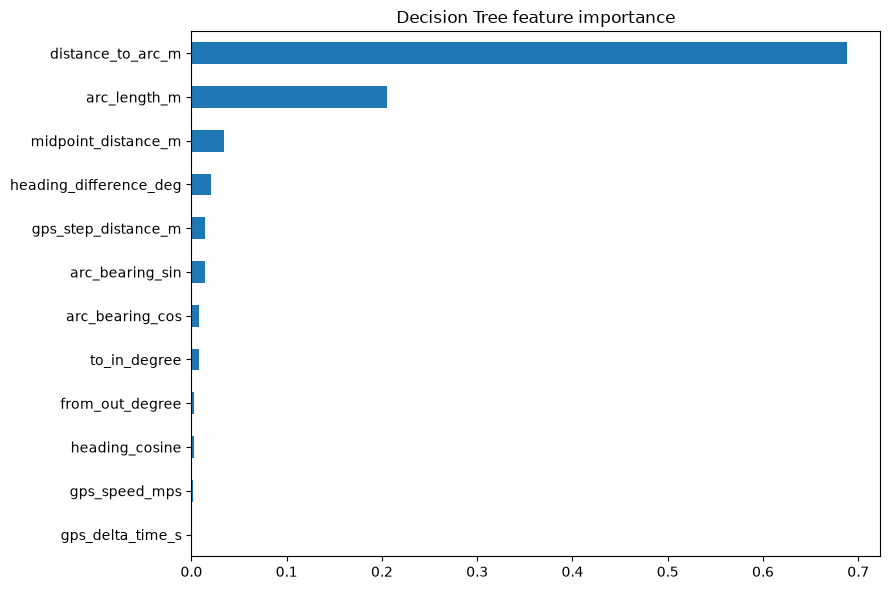

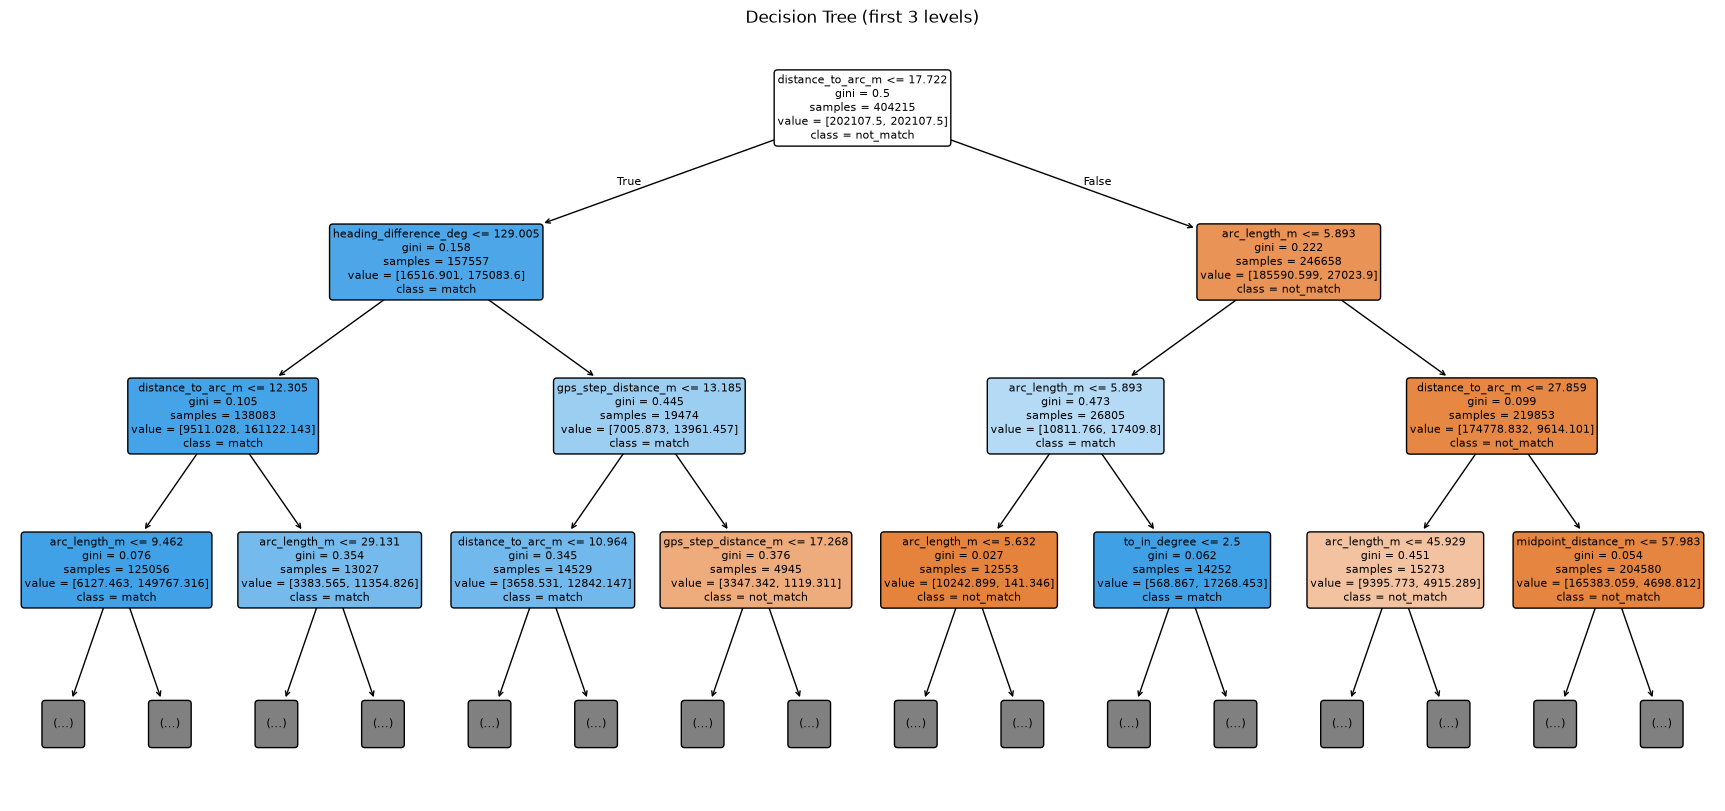

In [11]:
importance = pd.Series(tree.feature_importances_, index=FEATURE_COLUMNS).sort_values()
display(importance.sort_values(ascending=False).to_frame("importance"))
importance.plot(kind="barh", figsize=(9, 6), title="Decision Tree feature importance")
plt.tight_layout()
plt.show()

plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=FEATURE_COLUMNS, class_names=["not_match", "match"],
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title("Decision Tree (first 3 levels)")
plt.show()

## 12. Save model, feature schema, diagnostics and validation results

In [12]:
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)
dump(tree, OUTPUT_DIR / "pathsnap_decision_tree.joblib")
with open(OUTPUT_DIR / "decision_tree_metadata.json", "w") as f:
    json.dump({
        "model": "sklearn.tree.DecisionTreeClassifier",
        "feature_columns": FEATURE_COLUMNS,
        "random_state": RANDOM_STATE,
        "max_depth": 14,
        "min_samples_split": 20,
        "min_samples_leaf": 10,
        "candidate_k": K_ROAD_CANDIDATES,
        "route_alignment_k": K_ROUTE_ALIGNMENT,
        "max_candidate_distance_m": MAX_CANDIDATE_DISTANCE_M,
        "note": "Candidate-level classifier. Route-to-GPS labels are approximate monotonic geometric alignments; inspect diagnostics."
    }, f, indent=2)
candidate_df.to_csv(OUTPUT_DIR / "training_candidate_features.csv", index=False)
diagnostics_df.to_csv(OUTPUT_DIR / "route_alignment_diagnostics.csv", index=False)
fold_df.to_csv(OUTPUT_DIR / "decision_tree_group_cv_results.csv", index=False)
print("Saved artifacts to:", OUTPUT_DIR.resolve())

# Export a compact metrics file for the separate cross-model comparison cell.
pd.DataFrame([{
    "model": "Decision Tree",
    "validation_accuracy": accuracy_score(y_val, val_pred),
    "validation_macro_f1": f1_score(y_val, val_pred, average="macro", zero_division=0),
    "validation_positive_f1": f1_score(y_val, val_pred, zero_division=0),
    "validation_log_loss": log_loss(y_val, val_prob, labels=[0, 1]),
    "training_seconds": fit_seconds,
    "prediction_seconds": predict_seconds,
}]).to_csv(OUTPUT_DIR / "decision_tree_validation_metrics.csv", index=False)


Saved artifacts to: C:\Users\shiva\Downloads\artifacts


## 13. Important interpretation notes

- `is_match` is generated by geometric monotonic alignment of GPS observations to the provided ordered route. This is an inferred supervision method, not a direct label provided per GPS observation.
- The alignment method should be reviewed visually on several trips before reporting metrics.
- `candidate_miss_rate` measures whether the reference arc was present in the nearest-road candidate list. It is distinct from classifier error.
- The Decision Tree is a candidate scorer, not a complete sequence decoder. A later HMM/Viterbi stage can use these scores to enforce route continuity.
- Do not use `student_test/` or evaluator-only data for fitting or model selection.

## 14. Student-test evaluation

This section searches only the supplied `student_test` folder. It does not access the evaluator-only trips. It builds the same candidate features, scores them with this notebook's trained model, and reports candidate metrics plus observation-level Top-1 accuracy. The reference labels are still based on the notebook's geometric alignment procedure, so describe them as inferred labels.

In [13]:
# Find the student-test folder without touching evaluator-only data.
TEST_DIR_CANDIDATES = [
    DATA_ROOT / "student_test",
    DATA_ROOT / "student-test",
    DATA_ROOT / "student test",
    DATA_ROOT / "Student Test",
]
STUDENT_TEST_ROOT = next((p for p in TEST_DIR_CANDIDATES if p.is_dir()), None)
if STUDENT_TEST_ROOT is None:
    print("Student-test folder not found. Checked:", [str(p) for p in TEST_DIR_CANDIDATES])
else:
    test_dirs = sorted(p for p in STUDENT_TEST_ROOT.iterdir() if p.is_dir())
    print("Student-test trips found:", len(test_dirs))
    test_tables, test_diags = [], []
    for i, trip_dir in enumerate(test_dirs, 1):
        print(f"[{i}/{len(test_dirs)}] {trip_dir.name}")
        tab, diag = build_trip_table(trip_dir)
        test_tables.append(tab)
        test_diags.append(diag)
    student_test_df = pd.concat(test_tables, ignore_index=True)
    student_test_diagnostics = pd.DataFrame(test_diags)
    print("Student-test candidate table:", student_test_df.shape)
    display(student_test_diagnostics)


Student-test trips found: 10
[1/10] 00000000
[2/10] 00000007
[3/10] 00000009
[4/10] 00000040
[5/10] 00000052
[6/10] 00000056
[7/10] 00000065
[8/10] 00000076
[9/10] 00000077
[10/10] 00000091
Student-test candidate table: (574800, 16)


,trip_id,gps_observations,route_arcs,candidate_rows,alignment_median_distance_m,alignment_p90_distance_m,candidate_positive_coverage,candidate_miss_rate
0,00000000,2503,179,75090,6.052950,14.048297,0.957651,0.042349
1,00000007,1354,123,40620,4.515904,19.903710,1.000000,0.000000
2,00000009,1049,429,31470,4.705765,13.064979,0.992374,0.007626
3,00000040,2995,309,89850,4.923868,11.999874,0.973623,0.026377
4,00000052,262,95,7860,4.175926,10.663988,0.977099,0.022901
5,00000056,3958,1323,118740,4.864649,12.471281,0.980546,0.019454
6,00000065,768,145,23040,4.399613,9.855072,0.953125,0.046875
7,00000076,1486,374,44580,6.846830,15.661030,0.972409,0.027591
8,00000077,3911,268,117330,6.117400,15.098123,0.994119,0.005881
9,00000091,874,232,26220,4.385357,10.507734,0.987414,0.012586


## 15. Student-test metrics

In [14]:
MODEL_FOR_STUDENT_TEST = tree
MODEL_LABEL = 'Decision Tree'
STUDENT_METRICS_FILENAME = 'decision_tree_student_test_metrics.csv'

if STUDENT_TEST_ROOT is not None and "student_test_df" in globals():
    X_student = student_test_df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
    X_student = X_student.fillna(train_medians).astype(np.float32)
    student_prob = MODEL_FOR_STUDENT_TEST.predict_proba(X_student)[:, list(MODEL_FOR_STUDENT_TEST.classes_).index(1)]
    student_pred = (student_prob >= 0.5).astype(int)
    student_eval = student_test_df[["trip_id", "observation_id", "is_match"]].copy()
    student_eval["match_probability"] = student_prob
    top1 = student_eval.loc[student_eval.groupby(["trip_id", "observation_id"]).match_probability.idxmax()]
    candidate_coverage = student_eval.groupby(["trip_id", "observation_id"]).is_match.max().mean()
    student_metrics = {
        "model": MODEL_LABEL,
        "candidate_accuracy": accuracy_score(student_eval.is_match, student_pred),
        "candidate_macro_f1": f1_score(student_eval.is_match, student_pred, average="macro", zero_division=0),
        "observation_top1_accuracy": top1.is_match.mean(),
        "observation_macro_f1": f1_score(top1.is_match, (top1.match_probability >= 0.5).astype(int), average="macro", zero_division=0),
        "candidate_coverage": candidate_coverage,
        "candidate_miss_rate": 1-candidate_coverage,
        "log_loss": log_loss(student_eval.is_match, student_prob, labels=[0,1]),
    }
    display(pd.DataFrame([student_metrics]))
    pd.DataFrame([student_metrics]).to_csv(OUTPUT_DIR / STUDENT_METRICS_FILENAME, index=False)
else:
    print("Student-test evaluation skipped because its folder was not found.")


,model,candidate_accuracy,candidate_macro_f1,observation_top1_accuracy,observation_macro_f1,candidate_coverage,candidate_miss_rate,log_loss
0,Decision Tree,0.951421,0.768409,0.70428,0.473405,0.979802,0.020198,0.2511


## 16. EDA and required model visualisations

All plots below are calculated from actual candidate data and actual experiment outputs. These classifiers do not expose epoch-wise loss histories; no artificial learning curves are created.

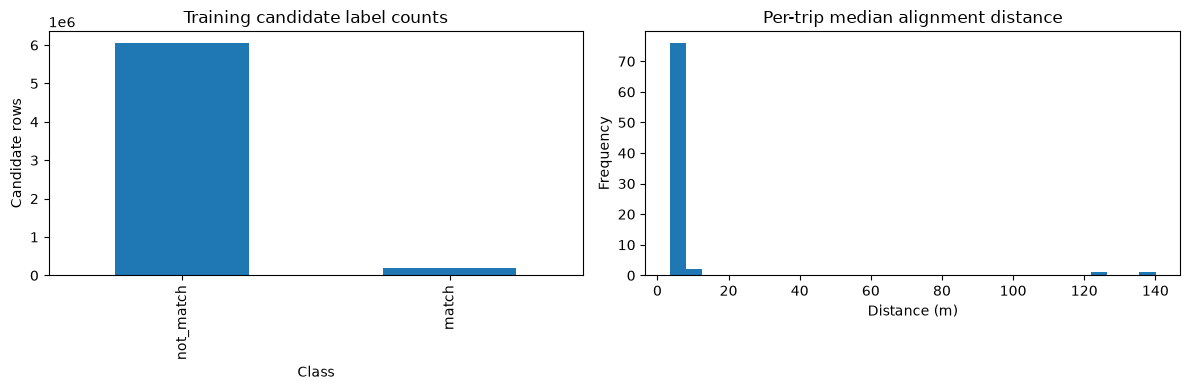

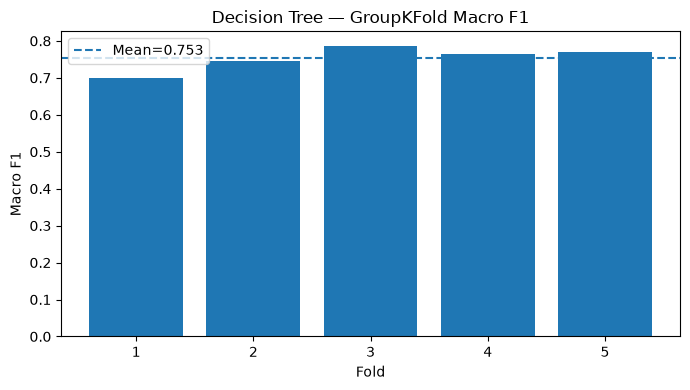

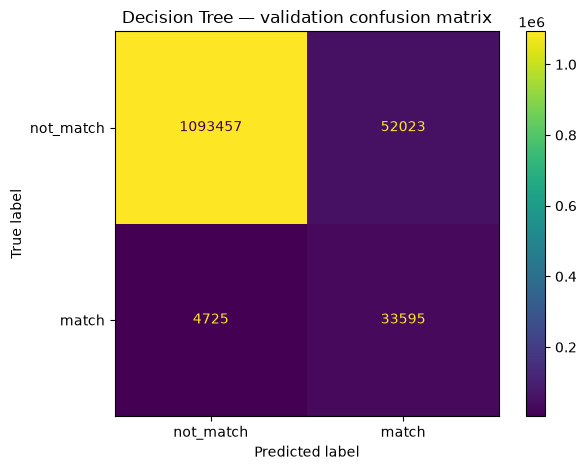

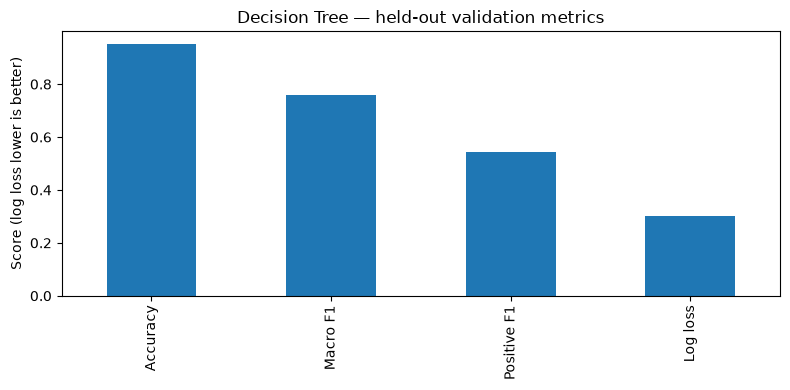

In [15]:
# EDA: actual candidate class distribution and alignment diagnostics.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
candidate_df["is_match"].value_counts().sort_index().rename(index={0:"not_match",1:"match"}).plot(
    kind="bar", ax=axes[0], title="Training candidate label counts"
)
axes[0].set_ylabel("Candidate rows")
axes[0].set_xlabel("Class")
diagnostics_df["alignment_median_distance_m"].plot(kind="hist", bins=30, ax=axes[1],
    title="Per-trip median alignment distance")
axes[1].set_xlabel("Distance (m)")
plt.tight_layout(); plt.show()

# Actual 5-fold CV Macro F1 for this model.
plt.figure(figsize=(7,4))
plt.bar(fold_df["fold"].astype(str), fold_df["macro_f1"])
plt.axhline(fold_df["macro_f1"].mean(), linestyle="--", label=f'Mean={fold_df["macro_f1"].mean():.3f}')
plt.title(MODEL_LABEL + " — GroupKFold Macro F1")
plt.xlabel("Fold"); plt.ylabel("Macro F1"); plt.legend(); plt.tight_layout(); plt.show()

# Actual held-out validation confusion matrix.
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=["not_match","match"], values_format="d")
plt.title(MODEL_LABEL + " — validation confusion matrix")
plt.tight_layout(); plt.show()

# Actual metric summary from held-out validation.
validation_plot = pd.Series({
    "Accuracy": accuracy_score(y_val, val_pred),
    "Macro F1": f1_score(y_val, val_pred, average="macro", zero_division=0),
    "Positive F1": f1_score(y_val, val_pred, zero_division=0),
    "Log loss": log_loss(y_val, val_prob, labels=[0,1]),
})
validation_plot.plot(kind="bar", figsize=(8,4), title=MODEL_LABEL + " — held-out validation metrics")
plt.ylabel("Score (log loss lower is better)"); plt.tight_layout(); plt.show()


## 17. Folium map for a selected training trip

The map overlays the observed GPS track and the reference route geometry for one training trip. It is a data visualisation, not a model-predicted route decoder.

In [16]:
%pip install -q folium
import folium
from IPython.display import display as ipy_display

def make_trip_map(trip_dir):
    trip_id = trip_dir.name
    track = read_ws(trip_dir / f"{trip_id}.track", ["longitude","latitude","timestamp_s"], float)
    nodes = read_ws(trip_dir / f"{trip_id}.nodes", ["longitude","latitude"], float)
    arcs = read_ws(trip_dir / f"{trip_id}.arcs", ["from_node_id","to_node_id"], np.int64)
    route = read_ws(trip_dir / f"{trip_id}.route", ["arc_id"], np.int64)["arc_id"].to_numpy()
    track = track.replace([np.inf,-np.inf], np.nan).dropna().sort_values("timestamp_s")
    track = track[track.longitude.between(-180,180) & track.latitude.between(-90,90)]
    center = [float(track.latitude.mean()), float(track.longitude.mean())]
    fmap = folium.Map(location=center, zoom_start=13, control_scale=True)
    gps_points = track[["latitude","longitude"]].to_numpy().tolist()
    folium.PolyLine(gps_points, color="blue", weight=4, opacity=0.8, tooltip="Observed GPS track").add_to(fmap)
    route_points = []
    for aid in route:
        a, b = arcs.iloc[int(aid)].to_numpy(dtype=int)
        route_points.extend([
            [float(nodes.iloc[a].latitude), float(nodes.iloc[a].longitude)],
            [float(nodes.iloc[b].latitude), float(nodes.iloc[b].longitude)]
        ])
    # Draw route arcs individually to avoid implying that non-contiguous arcs connect.
    for aid in route:
        a, b = arcs.iloc[int(aid)].to_numpy(dtype=int)
        segment = [
            [float(nodes.iloc[a].latitude), float(nodes.iloc[a].longitude)],
            [float(nodes.iloc[b].latitude), float(nodes.iloc[b].longitude)]
        ]
        folium.PolyLine(segment, color="red", weight=3, opacity=0.75, tooltip="Reference route arc").add_to(fmap)
    folium.LayerControl().add_to(fmap)
    return fmap

selected_trip = train_dirs[0]
display(make_trip_map(selected_trip))


Note: you may need to restart the kernel to use updated packages.


## 18. Compare the two separate notebooks

Run this section after running both notebooks so both metric CSVs exist in the shared `artifacts/` folder. Each notebook writes its own clearly named CSV files. If one notebook has not been run yet, this cell explains which file is missing.

In [17]:
from pathlib import Path
metric_files = [
    Path("artifacts/decision_tree_validation_metrics.csv"),
    Path("artifacts/hist_gradient_boosting_validation_metrics.csv"),
    Path("artifacts/decision_tree_student_test_metrics.csv"),
    Path("artifacts/hist_gradient_boosting_student_test_metrics.csv"),
]
missing = [str(p) for p in metric_files if not p.exists()]
if missing:
    print("Run both separate model notebooks first. Missing result files:")
    for name in missing: print(" -", name)
else:
    val_compare = pd.concat([
        pd.read_csv(metric_files[0]), pd.read_csv(metric_files[1])
    ], ignore_index=True)
    student_compare = pd.concat([
        pd.read_csv(metric_files[2]), pd.read_csv(metric_files[3])
    ], ignore_index=True)
    display(val_compare)
    display(student_compare)
    val_compare.set_index("model")[["validation_macro_f1"]].plot(kind="bar", figsize=(7,4), title="Validation Macro F1 — model comparison")
    plt.ylabel("Macro F1"); plt.tight_layout(); plt.show()
    student_compare.set_index("model")[["observation_top1_accuracy"]].plot(kind="bar", figsize=(7,4), title="Student-test Top-1 accuracy — model comparison")
    plt.ylabel("Top-1 accuracy"); plt.tight_layout(); plt.show()
    student_compare.set_index("model")[["candidate_macro_f1"]].plot(kind="bar", figsize=(7,4), title="Student-test candidate Macro F1 — model comparison")
    plt.ylabel("Macro F1"); plt.tight_layout(); plt.show()


Run both separate model notebooks first. Missing result files:
 - artifacts\hist_gradient_boosting_validation_metrics.csv
 - artifacts\hist_gradient_boosting_student_test_metrics.csv
